# 多分类神经网络在量子关联分类中的应用研究

Research on the application of multi-classification neural network in quantum correlation classification (MCNN-QCC)

## 概要

本课题将通过知名深度学习框架Pytorch搭建神经网络，分析QCC数据集，观察训练误差和验证误差随训练代数提高的变化。

## 作者

徐浩轩 集美大学 2023-12

GitHub：[ollyhsu/MCNN-QCC](https://github.com/ollyhsu/MCNN-QCC)


# 0.安装pytorch

## 0.1 下载Pytorch

打开浏览器，访问 [PyTorch官方网站](https://pytorch.org/)

在官网首页，你会看到一个“Get Started”（开始使用）的按钮或类似的链接，点击它

接下来，你可能需要选择一些选项，比如选择你的操作系统、安装方式（例如pip或conda）、Python版本等。根据你的需求进行选择，并点击相关选项

完成上述步骤后，网站会为你生成一个相应的安装命令。复制这个命令，它会类似于：

```bash
pip3 install torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu121
```

## 0.2验证安装成功

你可以运行以下代码单元来验证PyTorch的安装是否成功，并检查CUDA是否可用以及CUDA的版本：

In [1]:
import torch

# 检查CUDA是否可用
cuda_available = torch.cuda.is_available()
print("CUDA Available: ", cuda_available)

if cuda_available:
    # 打印CUDA设备数量
    device_count = torch.cuda.device_count()
    print("CUDA Device Count: ", device_count)

    # 打印CUDA版本
    cuda_version = torch.version.cuda
    print("CUDA Version: ", cuda_version)

CUDA Available:  True
CUDA Device Count:  1
CUDA Version:  12.1


运行此代码单元后，如果你看到输出显示CUDA可用、设备数量以及CUDA版本，则说明PyTorch已经成功安装，并且CUDA也可用

# 1 生成（下载）数据集

运行`genDataset.py` 文件，生成数据集至 `dataset` 目录下

数据集标签说明：

`0` for separable states, `1` for two-separable states, `2` for entangled states

# 2 导入数据集

In [2]:
import torch  # 导入pytorch
import numpy as np
from torch.utils.data import DataLoader, TensorDataset

# 准备数据
train_mixes = np.load('dataset/qcc_train_set_mixes.npy')
train_labels = np.load('dataset/qcc_train_set_labels.npy')
test_mixes = np.load('dataset/qcc_test_set_mixes.npy')
test_labels = np.load('dataset/qcc_test_set_labels.npy')

# Convert to PyTorch tensors
train_mixes_tensor = torch.tensor(train_mixes, dtype=torch.float32)
train_labels_tensor = torch.tensor(train_labels, dtype=torch.long)

test_mixes_tensor = torch.tensor(test_mixes, dtype=torch.float32)
test_labels_tensor = torch.tensor(test_labels, dtype=torch.long)

# Extract real and imaginary parts
train_mixes_real = train_mixes_tensor[:, :, :, 0]
train_mixes_imag = train_mixes_tensor[:, :, :, 1]

test_mixes_real = test_mixes_tensor[:, :, :, 0]
test_mixes_imag = test_mixes_tensor[:, :, :, 1]

# Complex tensor
train_mixes_complex = torch.stack((train_mixes_real, train_mixes_imag), dim=-1)
test_mixes_complex = torch.stack((test_mixes_real, test_mixes_imag), dim=-1)

# Create PyTorch datasets
train_dataset = TensorDataset(train_mixes_complex, train_labels_tensor)
test_dataset = TensorDataset(test_mixes_complex, test_labels_tensor)

train_dataloader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_dataloader = DataLoader(test_dataset, batch_size=64, shuffle=True)

print("Train Mixes Tensor Shape: ", train_mixes_tensor.shape)
print("Train Labels Tensor Shape: ", train_labels_tensor.shape)
print("Test Mixes Tensor Shape: ", test_mixes_tensor.shape)
print("Test Labels Tensor Shape: ", test_labels_tensor.shape)

print("Train Mixes ComplexShape: ", train_mixes_complex.shape)
print("Test Mixes ComplexShape: ", test_mixes_complex.shape)

print("Train Dataset Size: ", len(train_dataset))
print("Test Dataset Size: ", len(test_dataset))
print("Train Dataloader Size: ", len(train_dataloader))
print("Test Dataloader Size: ", len(test_dataloader))

Train Mixes Tensor Shape:  torch.Size([160000, 8, 8, 2])
Train Labels Tensor Shape:  torch.Size([160000])
Test Mixes Tensor Shape:  torch.Size([40000, 8, 8, 2])
Test Labels Tensor Shape:  torch.Size([40000])
Train Mixes ComplexShape:  torch.Size([160000, 8, 8, 2])
Test Mixes ComplexShape:  torch.Size([40000, 8, 8, 2])
Train Dataset Size:  160000
Test Dataset Size:  40000
Train Dataloader Size:  2500
Test Dataloader Size:  625


# 3 搭建神经网络模型

## 3.1 全连接神经网络

神经网络的输入为 8 * 8 * 2= 128 的张量

第一个隐含层包含256个神经元

第二个隐含层包含多128个神经元

第三个隐含层包含64个神经元

输出层输出3个结果，对应数据集量子态的3种分类

In [3]:
from torch import nn


# 定义四层全连接神经网络模型
class FCNNModel(nn.Module):
    def __init__(self):
        super(FCNNModel, self).__init__()
        self.fc1 = nn.Linear(128, 256)  # 第一个隐藏层，输入大小为128，输出大小为256
        self.fc2 = nn.Linear(256, 128)  # 第二个隐藏层，输入大小为256，输出大小为128
        self.fc3 = nn.Linear(128, 64)   # 第三个隐藏层，输入大小为128，输出大小为64
        self.fc4 = nn.Linear(64, 3)     # 输出层，输入大小为64，输出大小为3（类别数量）

    def forward(self, x):
        x = torch.flatten(x, 1)  # 将输入展平成一维张量
        x = torch.relu(self.fc1(x))  # 第一个隐藏层的激活函数为ReLU
        x = torch.relu(self.fc2(x))  # 第二个隐藏层的激活函数为ReLU
        x = torch.relu(self.fc3(x))  # 第三个隐藏层的激活函数为ReLU
        x = self.fc4(x)  # 输出层不需要激活函数，因为后面会使用交叉熵损失函数
        return x

In [4]:
# from tqdm import tqdm
import torch.optim as optim

# 实例化模型
model = FCNNModel()

# 定义损失函数和优化器
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

# 训练模型
num_epochs = 10
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model.to(device)
model.train()

# 将每次训练的训练误差和测试误差存储在这两个列表里，后面绘制误差变化折线图用
train_losses, test_losses, train_accs, test_accs = [], [], [], []

print('Start training')
for epoch in range(num_epochs):
    running_loss = 0.0
    correct_train = 0
    total_train = 0

    # for inputs, labels in tqdm(train_dataloader, desc=f'Epoch {epoch + 1}/{num_epochs}', leave=False):
    for inputs, labels in train_dataloader:
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * inputs.size(0)
        _, predicted = outputs.max(1)
        total_train += labels.size(0)
        correct_train += predicted.eq(labels).sum().item()

    # 每次学完一遍数据集，都进行以下测试操作
    model.eval()
    test_loss = 0.0
    correct_test = 0
    total_test = 0
    with torch.no_grad():
        # for inputs, labels in tqdm(test_dataloader, desc='Test', leave=False):
        for inputs, labels in test_dataloader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            test_loss += loss.item() * inputs.size(0)
            _, predicted = outputs.max(1)
            total_test += labels.size(0)
            correct_test += predicted.eq(labels).sum().item()

    train_loss = running_loss / len(train_dataset)
    train_acc = 100. * correct_train / total_train
    test_loss = test_loss / len(test_dataset)
    test_acc = 100. * correct_test / total_test

    # 恢复Dropout
    model.train()

    # 将训练误差和测试误差存在两个列表里，后面绘制误差变化折线图用
    train_losses.append(train_loss)
    test_losses.append(test_loss)
    train_accs.append(train_acc)
    test_accs.append(test_acc)
   
    print("Number: {}/{}  ".format(epoch + 1, num_epochs),
          "Train Loss: {:.4f}  ".format(train_loss),
          "Test Loss: {:.4f}  ".format(test_loss),
          "Model Test Accuracy: {:.3f}%".format(test_acc))

Start training
Number: 1/10   Train Loss: 0.0374   Test Loss: 0.0193   Model Test Accuracy: 99.013%
Number: 2/10   Train Loss: 0.0194   Test Loss: 0.0192   Model Test Accuracy: 99.028%
Number: 3/10   Train Loss: 0.0179   Test Loss: 0.0175   Model Test Accuracy: 99.020%
Number: 4/10   Train Loss: 0.0170   Test Loss: 0.0178   Model Test Accuracy: 99.028%
Number: 5/10   Train Loss: 0.0167   Test Loss: 0.0177   Model Test Accuracy: 98.990%
Number: 6/10   Train Loss: 0.0161   Test Loss: 0.0170   Model Test Accuracy: 98.978%
Number: 7/10   Train Loss: 0.0159   Test Loss: 0.0172   Model Test Accuracy: 99.020%
Number: 8/10   Train Loss: 0.0155   Test Loss: 0.0175   Model Test Accuracy: 99.020%
Number: 9/10   Train Loss: 0.0152   Test Loss: 0.0183   Model Test Accuracy: 98.900%
Number: 10/10   Train Loss: 0.0150   Test Loss: 0.0175   Model Test Accuracy: 98.993%


## 3.2 验证模型效果

绘制训练误差和测试误差随学习次数增加的变化

In [5]:
import matplotlib.pyplot as plt
%matplotlib inline

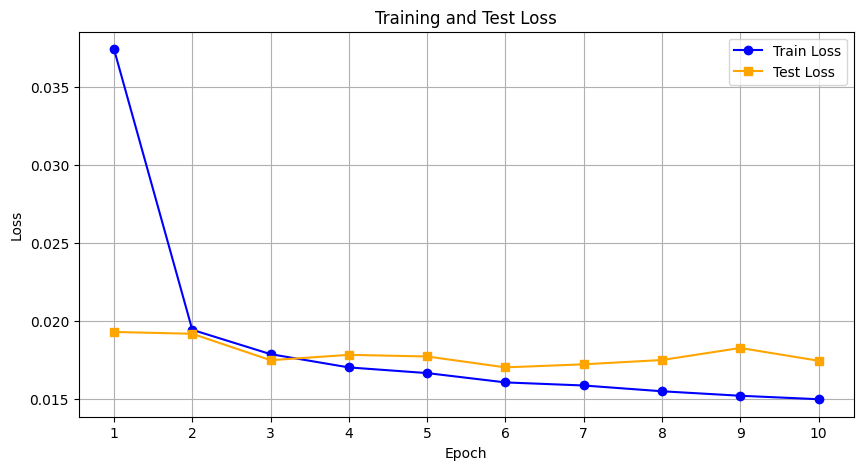

In [6]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"]="TRUE"
# 训练次数
epochs = range(1, len(train_losses) + 1)

# 绘制训练误差和测试误差随学习次数增加的变化曲线
plt.figure(figsize=(10, 5))
plt.plot(epochs, train_losses, label='Train Loss', color='blue', marker='o')
plt.plot(epochs, test_losses, label='Test Loss', color='orange', marker='s')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Test Loss')
plt.legend()
plt.grid(True)

# 设置 x 轴刻度为每个 epoch 单位
plt.xticks(range(1, len(train_losses) + 1))

plt.show()

## 3.3 采用Dropout方法防止过拟合

In [7]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class FCNNModelWithDropout(nn.Module):
    def __init__(self):
        super(FCNNModelWithDropout, self).__init__()
        self.fc1 = nn.Linear(8 * 8 * 2, 256)
        self.fc2 = nn.Linear(256, 128)
        self.fc3 = nn.Linear(128, 64)
        self.fc4 = nn.Linear(64, 3)
        self.dropout = nn.Dropout(p=0.5)  # 添加 Dropout 层，p 参数表示丢弃概率

    def forward(self, x):
        x = x.view(-1, 8 * 8 * 2)  # 展平输入数据
        x = F.relu(self.fc1(x))
        x = self.dropout(x)  # 在第一个全连接层后添加 Dropout
        x = F.relu(self.fc2(x))
        x = self.dropout(x)  # 在第二个全连接层后添加 Dropout
        x = F.relu(self.fc3(x))
        x = self.dropout(x)  # 在第三个全连接层后添加 Dropout
        x = self.fc4(x)
        return x

In [8]:
# from tqdm import tqdm
import torch.optim as optim

# 创建模型实例
model = FCNNModelWithDropout()

# 定义损失函数和优化器
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

# 训练模型
num_epochs = 10
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model.to(device)
model.train()

# 将每次训练的训练误差和测试误差存储在这两个列表里，后面绘制误差变化折线图用
train_losses, test_losses, train_accs, test_accs = [], [], [], []

print('Start training')
for epoch in range(num_epochs):
    running_loss = 0.0
    correct_train = 0
    total_train = 0

    # for inputs, labels in tqdm(train_dataloader, desc=f'Epoch {epoch + 1}/{num_epochs}', leave=False):
    for inputs, labels in train_dataloader:
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * inputs.size(0)
        _, predicted = outputs.max(1)
        total_train += labels.size(0)
        correct_train += predicted.eq(labels).sum().item()

    # 每次学完一遍数据集，都进行以下测试操作
    model.eval()
    test_loss = 0.0
    correct_test = 0
    total_test = 0
    with torch.no_grad():
        # for inputs, labels in tqdm(test_dataloader, desc='Test', leave=False):
        for inputs, labels in test_dataloader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            test_loss += loss.item() * inputs.size(0)
            _, predicted = outputs.max(1)
            total_test += labels.size(0)
            correct_test += predicted.eq(labels).sum().item()

    train_loss = running_loss / len(train_dataset)
    train_acc = 100. * correct_train / total_train
    test_loss = test_loss / len(test_dataset)
    test_acc = 100. * correct_test / total_test

    # 恢复Dropout
    model.train()

    # 将训练误差和测试误差存在两个列表里，后面绘制误差变化折线图用
    train_losses.append(train_loss)
    test_losses.append(test_loss)
    train_accs.append(train_acc)
    test_accs.append(test_acc)
   
    print("Number: {}/{}  ".format(epoch + 1, num_epochs),
          "Train Loss: {:.4f}  ".format(train_loss),
          "Test Loss: {:.4f}  ".format(test_loss),
          "Model Test Accuracy: {:.3f}%".format(test_acc))

Start training
Number: 1/10   Train Loss: 0.0485   Test Loss: 0.0198   Model Test Accuracy: 99.028%
Number: 2/10   Train Loss: 0.0223   Test Loss: 0.0188   Model Test Accuracy: 99.028%
Number: 3/10   Train Loss: 0.0210   Test Loss: 0.0193   Model Test Accuracy: 99.025%
Number: 4/10   Train Loss: 0.0200   Test Loss: 0.0176   Model Test Accuracy: 98.998%
Number: 5/10   Train Loss: 0.0194   Test Loss: 0.0175   Model Test Accuracy: 99.030%
Number: 6/10   Train Loss: 0.0191   Test Loss: 0.0172   Model Test Accuracy: 99.022%
Number: 7/10   Train Loss: 0.0190   Test Loss: 0.0170   Model Test Accuracy: 99.002%
Number: 8/10   Train Loss: 0.0186   Test Loss: 0.0174   Model Test Accuracy: 98.990%
Number: 9/10   Train Loss: 0.0187   Test Loss: 0.0169   Model Test Accuracy: 98.998%
Number: 10/10   Train Loss: 0.0181   Test Loss: 0.0169   Model Test Accuracy: 99.025%


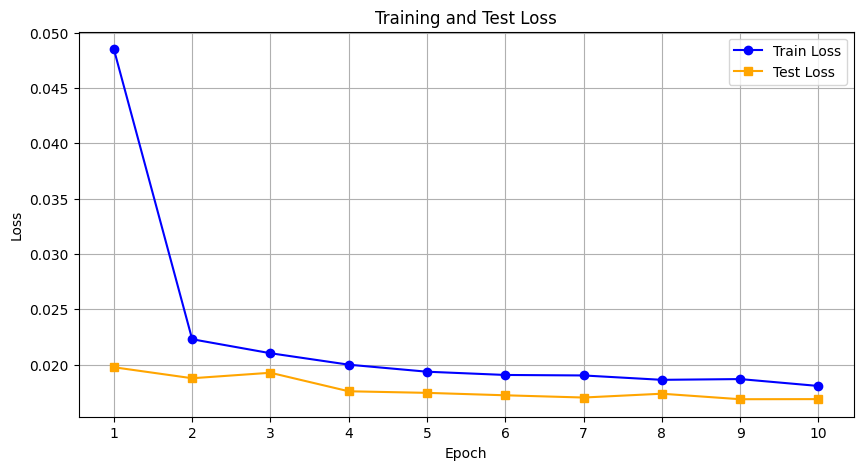

In [9]:
# 训练次数
epochs = range(1, len(train_losses) + 1)

# 绘制训练误差和测试误差随学习次数增加的变化曲线
plt.figure(figsize=(10, 5))
plt.plot(epochs, train_losses, label='Train Loss', color='blue', marker='o')
plt.plot(epochs, test_losses, label='Test Loss', color='orange', marker='s')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Test Loss')
plt.legend()
plt.grid(True)

# 设置 x 轴刻度为每个 epoch 单位
plt.xticks(range(1, len(train_losses) + 1))

plt.show()